# Water Segmentation — Week 2: Pretrained U-Net (12-channel) vs. Scratch U-Net

This notebook is **self-contained** and runs from a fresh Colab/Jupyter kernel.

## Pipeline

```
12-channel Multispectral Images
            │
            ▼
      Dataset + Masks
            │
      ┌─────┴─────┐
      ▼           ▼
 Scratch U-Net   Pretrained U-Net (ResNet-34 encoder, ImageNet weights)
 (Week 1)              │
                 First Conv → 12 channels
                       │
      └─────┬─────┘
            ▼
       Fine-tuning
            │
            ▼
       Test Evaluation
            │
     ┌──────┼────────┐
     ▼      ▼        ▼
    IoU     F1    Precision/Recall
            │
            ▼
      Model Comparison
            │
            ▼
       Final Findings
```

## Completion requirements → where they are met

| Requirement | Section |
|---|---|
| Pretrained segmentation model adapted to accept 12-channel input | §10–11 (`adapt_first_conv`, `PretrainedResNetUNet`) |
| Fine-tuned model achieves measurably higher validation IoU than the Week 1 scratch model | §13 (automatic check) |
| Comparison table (IoU, F1, Precision, Recall) in notebook/README | §13, §15 (README export) |
| Clean, modular code pushed to GitHub | §15 |

**Design note:** `segmentation-models-pytorch` is intentionally **not** used (it triggers Pillow/torchvision conflicts on Colab). The pretrained U-Net is built natively from a **torchvision ResNet-34** encoder with ImageNet weights plus a U-Net decoder, which gives the same architecture without the dependency problem.

**Fairness:** both models use the same split, normalisation, augmentation, loss, optimiser family, epoch budget and validation-only threshold selection. The test set is touched once per model, at the end.


In [1]:
# 0. Install dependencies
# Colab already ships torch, torchvision, numpy, pandas, scikit-learn, matplotlib, tqdm and Pillow.
# We install ONLY what is missing and do NOT use -U / --force-reinstall, because that upgrades
# numpy/pandas/requests past Colab's pinned versions (the dependency-conflict warnings) and can break imports.
!pip -q install rasterio gdown


## 1. Setup

In [2]:
# 2. Imports, reproducibility, and configuration
import os
import json
import random
import copy
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import rasterio
from sklearn.model_selection import train_test_split

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

# Dataset/configuration
DATASET_DIR = Path("/content/dataset")
IMAGE_DIR = DATASET_DIR / "images"
MASK_DIR = DATASET_DIR / "labels"
WORK_DIR = Path("/content/water_segmentation_runs")
WORK_DIR.mkdir(parents=True, exist_ok=True)

NUM_CHANNELS = 12
BAND_NAMES = ["B1","B2","B3","B4","B5","B6","B7","B8","B8A","B9","B11","B12"]

EPOCHS = 35
BATCH_SIZE = 4
PATCH_SIZE = 128
LR = 2e-4
NUM_WORKERS = 0
EARLY_STOPPING_PATIENCE = 8

# --- Week 2 settings -------------------------------------------------------
# Epoch budget is identical for both models (35 total) so the comparison is fair.
FREEZE_EPOCHS = 5            # phase 1: encoder frozen, decoder + new first conv train
FINETUNE_EPOCHS = EPOCHS - FREEZE_EPOCHS   # phase 2: whole network trains
LR_DECODER_P1 = 1e-3         # phase 1 learning rate (decoder / head / first conv)
LR_ENCODER_P2 = 1e-4         # phase 2: pretrained encoder (small LR to protect pretrained features)
LR_DECODER_P2 = 3e-4         # phase 2: randomly initialised decoder
RGB_BAND_IDX = (3, 2, 1)     # B4(R), B3(G), B2(B) positions inside BAND_NAMES

print("Dataset directory:", DATASET_DIR)


Device: cuda
Dataset directory: /content/dataset


## 2. Dataset + masks

In [3]:
# 3. Obtain the dataset
# This cell is self-contained. It does NOT mount Google Drive and does NOT depend on
# a cache or variable created by another notebook.
#
# If /content/dataset already exists, it is reused.
# Otherwise, the public shared folder is downloaded with gdown.

DATASET_FOLDER_ID = "1SBX6zHpgcsYHt5FuO0-o7wuYXJgMl-Zl"
DATASET_FOLDER_URL = f"https://drive.google.com/drive/folders/{DATASET_FOLDER_ID}"

def has_dataset(root: Path) -> bool:
    return (root / "images").is_dir() and (root / "labels").is_dir()

if not has_dataset(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    print("Dataset folders were not found. Downloading from Google Drive...")
    result = subprocess.run(
        ["gdown", "--folder", DATASET_FOLDER_URL, "-O", str(DATASET_DIR), "--remaining-ok"],
        text=True,
        capture_output=True,
    )
    print(result.stdout[-4000:])
    if result.returncode != 0:
        print(result.stderr[-4000:])

if not has_dataset(DATASET_DIR):
    raise FileNotFoundError(
        f"Could not find the expected dataset layout at {DATASET_DIR}. "
        "Expected: /content/dataset/images/*.tif and /content/dataset/labels/*.png. "
        "If the Google Drive folder is private/quota-limited, upload or extract the dataset "
        "into /content/dataset and rerun this cell."
    )

print("Dataset found:", DATASET_DIR)
print("Images:", IMAGE_DIR)
print("Labels:", MASK_DIR)


Dataset folders were not found. Downloading from Google Drive...
file 1cKFoM9ITbdveT9lomnH5HtJQ2puDqdlC 32.tif
Processing file 16YP2ZVrK9a51bJhWj0eLhuj7X9sL1Q2D 33.tif
Processing file 1rRO8vM2VWE2mKHZzL-2L0Bk5ZSVhaFZt 34.tif
Processing file 1o5iy_ZMAyrYxGvYVf1HURtO_ySAqtXL4 35.tif
Processing file 1Z9g-4wzJyB3xlpYOokfDcfVBzqaVFBr0 36.tif
Processing file 1z40H6otXN12Zm63_14juyJ_gKGJMvs0W 37.tif
Processing file 1u7HuL8_ydD0oEdqGF54xfXxOUs_6uUFb 38.tif
Processing file 1Zp9KEM6Ej5AeBXEUJIT32BxnmhnMCr0c 39.tif
Processing file 1fObIS0UddWHVR1tGMhxbdJ6mUQ7dL9te 40.tif
Processing file 1M1TfqU6SlR1cvx02ZbNNtwNg78vK0ww2 41.tif
Processing file 1CZuqDqTPs7Fl6yhJ55Kbg6JPAmn7oz2f 42.tif
Processing file 18APsv5Eo0mK7TBSjQ6Q0XjzPN8HB4-ay 43.tif
Processing file 1ekm1j7po9y3adOXxntWMcD6wG4p3aF6b 44.tif
Processing file 16EDwZ9yY_5Zg66-xtEFQBB2t3cypBmIs 45.tif
Processing file 1a92fzYpIlrP3_pI7Ej4PfxNmIpfRA3co 46.tif
Processing file 1I3cr39PAl0pQOd2aY_hEwPVuYOrPqxat 47.tif
Processing file 11fsy2s0Mi2mmf9rno

In [4]:
# 4. Discover and pair the actual image/label files
def numeric_stem(path: Path):
    try:
        return int(path.stem)
    except ValueError:
        return None

image_files = sorted(
    [p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in {".tif", ".tiff"}],
    key=lambda p: (numeric_stem(p) is None, numeric_stem(p) if numeric_stem(p) is not None else p.name),
)

mask_files = sorted(
    [p for p in MASK_DIR.iterdir() if p.suffix.lower() == ".png"],
    key=lambda p: p.name,
)

# Exact mask names are preferred: 10.png beats 10_244.png.
masks_by_exact_stem = {p.stem: p for p in mask_files}
masks_by_id = {}
for p in mask_files:
    base_id = p.stem.split("_", 1)[0]
    masks_by_id.setdefault(base_id, []).append(p)

pairs = []
pair_rows = []

for image_path in image_files:
    image_id = image_path.stem
    mask_path = masks_by_exact_stem.get(image_id)

    if mask_path is None:
        candidates = masks_by_id.get(image_id, [])
        if len(candidates) == 1:
            mask_path = candidates[0]
        elif len(candidates) > 1:
            # Deterministic fallback; exact names should have handled the common case.
            mask_path = sorted(candidates, key=lambda p: p.name)[0]

    if mask_path is not None:
        pairs.append((image_path, mask_path))
        pair_rows.append({
            "image_id": image_id,
            "image": image_path.name,
            "mask": mask_path.name,
            "mask_selection": "exact" if mask_path.stem == image_id else "suffixed_fallback",
        })

pair_df = pd.DataFrame(pair_rows)

print(f"Total GeoTIFF images: {len(image_files)}")
print(f"Total PNG labels:      {len(mask_files)}")
print(f"Usable labeled pairs:  {len(pairs)}")
print(f"Unlabeled images:      {len(image_files) - len(pairs)}")

if not pair_df.empty:
    display(pair_df)

if len(pairs) < 3:
    raise RuntimeError(
        "Fewer than 3 labeled image/mask pairs were found. "
        "Check the dataset folders and filenames."
    )


Total GeoTIFF images: 50
Total PNG labels:      31
Usable labeled pairs:  16
Unlabeled images:      34


,image_id,image,mask,mask_selection
0,0,0.tif,0.png,exact
1,1,1.tif,1.png,exact
2,2,2.tif,2.png,exact
3,3,3.tif,3.png,exact
4,4,4.tif,4.png,exact
5,5,5.tif,5.png,exact
6,6,6.tif,6.png,exact
7,7,7.tif,7.png,exact
8,8,8.tif,8.png,exact
9,9,9.tif,9.png,exact


In [5]:
# 5. Validate image/mask shapes and label values
for image_path, mask_path in pairs[:10]:
    with rasterio.open(image_path) as src:
        shape = (src.count, src.height, src.width)
    with Image.open(mask_path) as im:
        mask_shape = im.size[::-1]  # H, W
        mask_values = np.unique(np.asarray(im))
    print(
        f"{image_path.name:>8} | image={shape} | mask={mask_shape} "
        f"| mask values={mask_values[:10]}"
    )

# Validate every pair before loading the full dataset.
for image_path, mask_path in pairs:
    with rasterio.open(image_path) as src:
        if src.count != NUM_CHANNELS:
            raise ValueError(
                f"{image_path.name} has {src.count} bands; expected {NUM_CHANNELS}."
            )
        image_hw = (src.height, src.width)

    with Image.open(mask_path) as im:
        mask_hw = im.size[::-1]

    if image_hw != mask_hw:
        raise ValueError(
            f"Shape mismatch for {image_path.name} / {mask_path.name}: "
            f"{image_hw} vs {mask_hw}"
        )

print("\nAll selected image/mask pairs passed the structural checks.")


   0.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   1.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   2.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   3.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   4.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   5.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0]
   6.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   7.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   8.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]
   9.tif | image=(12, 128, 128) | mask=(128, 128) | mask values=[0 1]

All selected image/mask pairs passed the structural checks.


/usr/local/lib/python3.13/dist-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


In [6]:
# 6. Load the labeled dataset into memory
X_list, Y_list, IDS = [], [], []

for image_path, mask_path in tqdm(pairs, desc="Reading labeled pairs"):
    with rasterio.open(image_path) as src:
        x = src.read().astype(np.float32)  # C,H,W

    with Image.open(mask_path) as im:
        mask = np.asarray(im, dtype=np.uint8)

    # Convert any nonzero label to foreground water.
    y = (mask > 0).astype(np.uint8)

    X_list.append(x)
    Y_list.append(y)
    IDS.append(image_path.stem)

X = np.stack(X_list, axis=0)
Y = np.stack(Y_list, axis=0)

print("X shape:", X.shape, X.dtype)
print("Y shape:", Y.shape, Y.dtype)
print("Positive-water fraction:", f"{Y.mean():.3%}")

# Record per-image label coverage for transparency.
coverage = pd.DataFrame({
    "image_id": IDS,
    "water_fraction": [float(Y[i].mean()) for i in range(len(Y))]
})
display(coverage)


Reading labeled pairs:   0%|          | 0/16 [00:00<?, ?it/s]

X shape: (16, 12, 128, 128) float32
Y shape: (16, 128, 128) uint8
Positive-water fraction: 21.267%


,image_id,water_fraction
0,0,0.117004
1,1,0.011108
2,2,0.718262
3,3,0.053162
4,4,0.019836
5,5,0.000000
6,6,0.017029
7,7,0.002319
8,8,0.151978
9,9,0.415344


In [7]:
# 7. Train/validation/test split and train-only normalization
idx = np.arange(len(X))

# Keep the split reproducible and independent of previous notebook state.
train_idx, hold_idx = train_test_split(
    idx, test_size=0.30, random_state=SEED, shuffle=True
)
val_idx, test_idx = train_test_split(
    hold_idx, test_size=0.50, random_state=SEED, shuffle=True
)

# Sentinel-style integer reflectance is commonly stored around 0..10000.
train_sample = X[train_idx]
scale = 10000.0 if np.nanpercentile(train_sample, 99.9) > 2 else 1.0
X = X.astype(np.float32) / scale

# Compute normalization statistics from TRAIN ONLY to avoid test leakage.
sampled_pixels = []
for i in train_idx:
    flat = X[i].reshape(NUM_CHANNELS, -1)
    step = max(1, flat.shape[1] // 20000)
    sampled_pixels.append(flat[:, ::step])

train_pixels = np.concatenate(sampled_pixels, axis=1)
mean = np.nanmean(train_pixels, axis=1).astype(np.float32)
std = np.nanstd(train_pixels, axis=1).astype(np.float32)
std = np.maximum(std, 1e-6)

X = (X - mean[None, :, None, None]) / std[None, :, None, None]
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

print(f"Split: train={len(train_idx)}, val={len(val_idx)}, test={len(test_idx)}")
print(
    "Water fraction | "
    f"train={Y[train_idx].mean():.3%}, "
    f"val={Y[val_idx].mean():.3%}, "
    f"test={Y[test_idx].mean():.3%}"
)


Split: train=11, val=2, test=3
Water fraction | train=29.660%, val=5.850%, test=0.769%


In [8]:
# 8. PyTorch dataset and loaders
class WaterDataset(Dataset):
    def __init__(self, indices, train=False):
        self.indices = list(indices)
        self.train = train

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, j):
        i = self.indices[j]
        x = X[i].copy()
        y = Y[i].copy()

        if self.train:
            if random.random() < 0.5:
                x = x[:, :, ::-1].copy()
                y = y[:, ::-1].copy()

            if random.random() < 0.5:
                x = x[:, ::-1, :].copy()
                y = y[::-1, :].copy()

            k = random.randrange(4)
            if k:
                x = np.rot90(x, k, axes=(1, 2)).copy()
                y = np.rot90(y, k).copy()

        xt = torch.from_numpy(x).float()
        yt = torch.from_numpy(y.astype(np.float32))[None]

        if xt.shape[-2:] != (PATCH_SIZE, PATCH_SIZE):
            xt = F.interpolate(
                xt[None],
                size=(PATCH_SIZE, PATCH_SIZE),
                mode="bilinear",
                align_corners=False,
            )[0]
            yt = F.interpolate(
                yt[None],
                size=(PATCH_SIZE, PATCH_SIZE),
                mode="nearest",
            )[0]

        return xt, yt

train_loader = DataLoader(
    WaterDataset(train_idx, train=True),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)
val_loader = DataLoader(
    WaterDataset(val_idx),
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS,
)
test_loader = DataLoader(
    WaterDataset(test_idx),
    batch_size=1,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))


Train batches: 3
Val batches: 2
Test batches: 3


## 7. Model building blocks and the Week 1 scratch U-Net

`DoubleConv`, `Down` and `Up` are shared by both models. `WaterUNet` is the unchanged Week 1 baseline (random initialisation).

In [9]:
# 9. Building blocks + scratch U-Net (Week 1 baseline)
# A small native PyTorch U-Net is used instead of segmentation_models_pytorch.
# This keeps the notebook independent from torchvision/Pillow compatibility issues
# and supports 12-channel multispectral input directly.

class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class Down(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_channels, out_channels),
        )

    def forward(self, x):
        return self.pool_conv(x)


class Up(nn.Module):
    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, in_channels // 2, 2, stride=2)
        self.conv = DoubleConv(in_channels // 2 + skip_channels, out_channels)

    def forward(self, x, skip):
        x = self.up(x)

        # Handles odd spatial sizes safely.
        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)
        if diff_y != 0 or diff_x != 0:
            x = F.pad(
                x,
                [diff_x // 2, diff_x - diff_x // 2,
                 diff_y // 2, diff_y - diff_y // 2]
            )

        x = torch.cat([skip, x], dim=1)
        return self.conv(x)


class WaterUNet(nn.Module):
    def __init__(self, in_channels=12, out_channels=1):
        super().__init__()

        self.inc = DoubleConv(in_channels, 32)
        self.down1 = Down(32, 64)
        self.down2 = Down(64, 128)
        self.down3 = Down(128, 256)

        self.bottleneck = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(256, 512),
        )

        self.up1 = Up(512, 256, 256)
        self.up2 = Up(256, 128, 128)
        self.up3 = Up(128, 64, 64)
        self.up4 = Up(64, 32, 32)

        self.outc = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.bottleneck(x4)

        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)
        return self.outc(x)


## 8. Shared loss, metrics, training loop and threshold selection

These utilities take the model as an argument, so the **same code path** trains and evaluates both models.

In [10]:
# 10. Shared utilities: loss, metrics, evaluation, training loop, threshold search
def dice_loss(logits, targets, eps=1e-6):
    probs = torch.sigmoid(logits)
    dims = (1, 2, 3)
    inter = (probs * targets).sum(dims)
    denom = probs.sum(dims) + targets.sum(dims)
    return (1 - (2 * inter + eps) / (denom + eps)).mean()


def loss_fn(logits, targets):
    bce = F.binary_cross_entropy_with_logits(logits, targets)
    return 0.5 * bce + 0.5 * dice_loss(logits, targets)


def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def count_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if (p.requires_grad or not trainable_only))


def confusion_metrics(tp, fp, fn, tn, eps=1e-9):
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)
    iou = tp / (tp + fp + fn + eps)
    return {"IoU": float(iou), "F1": float(f1), "Precision": float(precision),
            "Recall": float(recall), "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn)}


@torch.no_grad()
def evaluate(model, loader, threshold=0.5):
    model.eval()
    tp = fp = fn = tn = 0
    losses = []
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logits = model(xb)
        losses.append(loss_fn(logits, yb).item())
        pred = torch.sigmoid(logits) >= threshold
        truth = yb >= 0.5
        tp += int((pred & truth).sum()); fp += int((pred & ~truth).sum())
        fn += int((~pred & truth).sum()); tn += int((~pred & ~truth).sum())
    out = confusion_metrics(tp, fp, fn, tn)
    out["loss"] = float(np.mean(losses)) if losses else float("nan")
    return out


def fit(model, name, optimizer, scheduler, epochs, patience, ckpt_path,
        history=None, best_iou=-1.0, phase="train"):
    """Train with validation-IoU checkpointing and early stopping.
    `history` / `best_iou` can be carried over so multi-phase fine-tuning keeps one record."""
    history = [] if history is None else history
    wait = 0
    for _ in range(epochs):
        epoch = len(history) + 1
        model.train()
        running = []
        bar = tqdm(train_loader, desc=f"[{name}|{phase}] epoch {epoch}", leave=False)
        for xb, yb in bar:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb), yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            running.append(loss.item())
            bar.set_postfix(loss=f"{np.mean(running):.4f}")

        val = evaluate(model, val_loader, 0.5)
        scheduler.step(val["IoU"])
        row = {"model": name, "phase": phase, "epoch": epoch,
               "train_loss": float(np.mean(running)),
               **{f"val_{k}": v for k, v in val.items() if k in ("loss", "IoU", "F1", "Precision", "Recall")}}
        history.append(row)
        print(f"[{name}|{phase}] ep {epoch:02d} train_loss={row['train_loss']:.4f} "
              f"val_loss={val['loss']:.4f} val_IoU={val['IoU']:.4f} val_F1={val['F1']:.4f}")

        if val["IoU"] > best_iou:
            best_iou = val["IoU"]
            torch.save({"model": model.state_dict(), "epoch": epoch, "val_metrics": val,
                        "mean": mean, "std": std, "scale": scale}, ckpt_path)
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"[{name}|{phase}] early stopping.")
                break
    return history, best_iou


@torch.no_grad()
def collect_probs(model, loader):
    model.eval()
    probs_all, masks_all = [], []
    for xb, yb in loader:
        probs_all.append(torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy().reshape(-1))
        masks_all.append(yb.numpy().reshape(-1).astype(bool))
    return np.concatenate(probs_all), np.concatenate(masks_all)


def select_threshold(model, loader):
    """Pick the probability threshold on VALIDATION data only (max F1, ties broken by IoU)."""
    probs, truth = collect_probs(model, loader)
    rows = []
    for t in np.arange(0.10, 0.91, 0.02):
        pred = probs >= t
        m = confusion_metrics((pred & truth).sum(), (pred & ~truth).sum(),
                              (~pred & truth).sum(), (~pred & ~truth).sum())
        rows.append({"threshold": float(t), **{k: m[k] for k in ("F1", "IoU", "Precision", "Recall")}})
    df = pd.DataFrame(rows).sort_values(["F1", "IoU"], ascending=False)
    return float(df.iloc[0]["threshold"]), df


RESULTS = {}   # model name -> dict of everything needed for the comparison
HISTORIES = {} # model name -> training history DataFrame
print("Utilities ready.")


Utilities ready.


## 9. Model A — Scratch U-Net (Week 1 baseline)

Random initialisation, trained end-to-end with the shared training loop.

In [11]:
# 11. Train Model A: scratch U-Net
SCRATCH = "Scratch U-Net"
seed_everything()
scratch_model = WaterUNet(in_channels=NUM_CHANNELS, out_channels=1).to(DEVICE)
scratch_ckpt = WORK_DIR / "best_scratch_unet.pth"

opt = torch.optim.AdamW(scratch_model.parameters(), lr=LR, weight_decay=1e-4)
sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=3)

hist, scratch_best_iou = fit(scratch_model, SCRATCH, opt, sch, EPOCHS,
                             EARLY_STOPPING_PATIENCE, scratch_ckpt, phase="scratch")
HISTORIES[SCRATCH] = pd.DataFrame(hist)
HISTORIES[SCRATCH].to_csv(WORK_DIR / "history_scratch.csv", index=False)

scratch_model.load_state_dict(torch.load(scratch_ckpt, map_location=DEVICE, weights_only=False)["model"])
print(f"\n{SCRATCH}: params={count_params(scratch_model):,} | best val IoU={scratch_best_iou:.4f}")


[Scratch U-Net|scratch] epoch 1:   0%|          | 0/3 [00:00<?, ?it/s]

[Scratch U-Net|scratch] ep 01 train_loss=0.7021 val_loss=0.7761 val_IoU=0.0000 val_F1=0.0000


[Scratch U-Net|scratch] epoch 2:   0%|          | 0/3 [00:00<?, ?it/s]

[Scratch U-Net|scratch] ep 02 train_loss=0.6693 val_loss=0.7753 val_IoU=0.0000 val_F1=0.0000


[Scratch U-Net|scratch] epoch 3:   0%|          | 0/3 [00:00<?, ?it/s]

...

[Scratch U-Net|scratch] ep 24 train_loss=0.4226 val_loss=0.5451 val_IoU=0.6118 val_F1=0.7591


[Scratch U-Net|scratch] epoch 25:   0%|          | 0/3 [00:00<?, ?it/s]

[Scratch U-Net|scratch] ep 25 train_loss=0.4262 val_loss=0.5363 val_IoU=0.6509 val_F1=0.7885


[Scratch U-Net|scratch] epoch 26:   0%|          | 0/3 [00:00<?, ?it/s]

[Scratch U-Net|scratch] ep 26 train_loss=0.4893 val_loss=0.5172 val_IoU=0.6730 val_F1=0.8045
[Scratch U-Net|scratch] early stopping.

Scratch U-Net: params=7,765,633 | best val IoU=0.6834


## 10. Adapting a pretrained encoder to 12 channels

ImageNet encoders expect **3-channel RGB**; our input has **12 Sentinel-2 bands**. Only the **first convolution** has a shape that depends on the number of input channels (`64 × 3 × 7 × 7`), so it is the only layer that must change. Everything deeper (`layer1`–`layer4`) keeps its pretrained weights unchanged.

**Weight-transfer strategy for the new `64 × 12 × 7 × 7` kernel**

1. Start every channel from the **mean of the three pretrained RGB filters** (a sensible, neutral edge/texture detector for non-visible bands).
2. Copy the true pretrained R, G, B filters into the matching bands **B4, B3, B2**.
3. Multiply by `3 / 12` so the first layer's output magnitude stays close to what the pretrained network expects, rather than growing 4× from summing 12 channels.

This keeps the visible bands "ImageNet-aware" while letting the other 9 bands (NIR, red-edge, SWIR — very informative for water) learn from a stable starting point.

In [12]:
# 12. 12-channel adaptation + pretrained ResNet-34 U-Net
def adapt_first_conv(conv: nn.Conv2d, in_channels: int, rgb_idx=RGB_BAND_IDX) -> nn.Conv2d:
    """Return a new first conv accepting `in_channels`, initialised from pretrained RGB weights."""
    w = conv.weight.data                                   # (out, 3, k, k) in R,G,B order
    new_w = w.mean(dim=1, keepdim=True).repeat(1, in_channels, 1, 1)   # neutral init for all bands
    for src_c, band in enumerate(rgb_idx):                 # put R,G,B filters on B4,B3,B2
        new_w[:, band] = w[:, src_c]
    new_w = new_w * (3.0 / in_channels)                    # keep activation scale comparable

    new_conv = nn.Conv2d(in_channels, conv.out_channels, kernel_size=conv.kernel_size,
                         stride=conv.stride, padding=conv.padding, bias=False)
    new_conv.weight.data.copy_(new_w)
    return new_conv


class PretrainedResNetUNet(nn.Module):
    """U-Net with an ImageNet-pretrained ResNet-34 encoder and a 12-channel first conv.

    Encoder feature maps for an HxW input:
        x0: 64  @ H/2   (conv1)      x1: 64  @ H/4   (layer1)
        x2: 128 @ H/8   (layer2)     x3: 256 @ H/16  (layer3)     x4: 512 @ H/32 (layer4)
    """
    def __init__(self, in_channels=12, out_channels=1, pretrained=True):
        super().__init__()
        from torchvision.models import resnet34, ResNet34_Weights
        try:
            backbone = resnet34(weights=ResNet34_Weights.IMAGENET1K_V1 if pretrained else None)
        except Exception as e:
            raise RuntimeError(
                "Could not load ImageNet weights (needs internet access to download.pytorch.org). "
                "Enable internet in the runtime and rerun this cell. Not falling back to random "
                "weights because that would invalidate the pretrained-vs-scratch comparison."
            ) from e

        # --- encoder (pretrained) ---
        self.conv1 = adapt_first_conv(backbone.conv1, in_channels) if in_channels != 3 else backbone.conv1
        self.bn1, self.relu, self.maxpool = backbone.bn1, backbone.relu, backbone.maxpool
        self.layer1, self.layer2 = backbone.layer1, backbone.layer2
        self.layer3, self.layer4 = backbone.layer3, backbone.layer4

        # --- decoder (random init), reusing the Up block from the scratch model ---
        self.up1 = Up(512, 256, 256)
        self.up2 = Up(256, 128, 128)
        self.up3 = Up(128, 64, 64)
        self.up4 = Up(64, 64, 32)
        self.final_up = nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2)
        self.final_conv = DoubleConv(16, 16)
        self.outc = nn.Conv2d(16, out_channels, kernel_size=1)

    def encoder_modules(self):
        return [self.conv1, self.bn1, self.layer1, self.layer2, self.layer3, self.layer4]

    def decoder_modules(self):
        return [self.up1, self.up2, self.up3, self.up4, self.final_up, self.final_conv, self.outc]

    def forward(self, x):
        x0 = self.relu(self.bn1(self.conv1(x)))
        x1 = self.layer1(self.maxpool(x0))
        x2 = self.layer2(x1)
        x3 = self.layer3(x2)
        x4 = self.layer4(x3)

        d = self.up1(x4, x3)
        d = self.up2(d, x2)
        d = self.up3(d, x1)
        d = self.up4(d, x0)
        d = self.final_conv(self.final_up(d))
        return self.outc(d)


seed_everything()
pre_model = PretrainedResNetUNet(in_channels=NUM_CHANNELS, out_channels=1, pretrained=True).to(DEVICE)

# ---- Verify the 12-channel adaptation (requirement 1) ----
assert pre_model.conv1.weight.shape == (64, NUM_CHANNELS, 7, 7), pre_model.conv1.weight.shape
with torch.no_grad():
    dummy = torch.randn(2, NUM_CHANNELS, PATCH_SIZE, PATCH_SIZE, device=DEVICE)
    out = pre_model.eval()(dummy)
assert out.shape == (2, 1, PATCH_SIZE, PATCH_SIZE), out.shape

print("First conv weight shape :", tuple(pre_model.conv1.weight.shape), "(was (64, 3, 7, 7))")
print("12-channel forward pass :", tuple(dummy.shape), "->", tuple(out.shape))
print(f"Pretrained U-Net params : {count_params(pre_model):,}  |  Scratch U-Net params: {count_params(scratch_model):,}")


Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 142MB/s]


First conv weight shape : (64, 12, 7, 7) (was (64, 3, 7, 7))
12-channel forward pass : (2, 12, 128, 128) -> (2, 1, 128, 128)
Pretrained U-Net params : 24,377,665  |  Scratch U-Net params: 7,765,633


## 11. Fine-tuning the pretrained U-Net (two phases)

| Phase | What trains | Why |
|---|---|---|
| **1 — warm-up** (`FREEZE_EPOCHS`) | decoder, head, **new 12-channel first conv** (+ its BatchNorm); `layer1–4` frozen | The decoder starts random; letting its large gradients flow into pretrained layers would damage the ImageNet features. |
| **2 — fine-tune** (`FINETUNE_EPOCHS`) | everything, with **discriminative LRs** (encoder `1e-4`, decoder `3e-4`) | Gently adapts ImageNet features to multispectral water imagery. |

Total epochs equal the scratch model's budget.

In [13]:
# 13. Fine-tune the pretrained U-Net
PRE = "Pretrained U-Net (ResNet-34)"
pre_ckpt = WORK_DIR / "best_pretrained_unet.pth"

def set_trainable(modules, flag):
    for m in modules:
        for p in m.parameters():
            p.requires_grad = flag

# ---------- Phase 1: freeze deep encoder, train decoder + new first conv ----------
set_trainable(pre_model.encoder_modules(), False)
set_trainable([pre_model.conv1, pre_model.bn1], True)       # new input layer must learn
p1_params = [p for p in pre_model.parameters() if p.requires_grad]
print(f"Phase 1 trainable params: {count_params(pre_model, trainable_only=True):,}")

opt1 = torch.optim.AdamW(p1_params, lr=LR_DECODER_P1, weight_decay=1e-4)
sch1 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt1, mode="max", factor=0.5, patience=2)
hist, best = fit(pre_model, PRE, opt1, sch1, FREEZE_EPOCHS, patience=FREEZE_EPOCHS,
                 ckpt_path=pre_ckpt, phase="1-warmup")

# ---------- Phase 2: unfreeze everything, discriminative learning rates ----------
set_trainable(pre_model.encoder_modules(), True)
print(f"Phase 2 trainable params: {count_params(pre_model, trainable_only=True):,}")

opt2 = torch.optim.AdamW([
    {"params": [p for m in pre_model.encoder_modules() for p in m.parameters()], "lr": LR_ENCODER_P2},
    {"params": [p for m in pre_model.decoder_modules() for p in m.parameters()], "lr": LR_DECODER_P2},
], weight_decay=1e-4)
sch2 = torch.optim.lr_scheduler.ReduceLROnPlateau(opt2, mode="max", factor=0.5, patience=3)
hist, pre_best_iou = fit(pre_model, PRE, opt2, sch2, FINETUNE_EPOCHS, EARLY_STOPPING_PATIENCE,
                         pre_ckpt, history=hist, best_iou=best, phase="2-finetune")

HISTORIES[PRE] = pd.DataFrame(hist)
HISTORIES[PRE].to_csv(WORK_DIR / "history_pretrained.csv", index=False)

pre_model.load_state_dict(torch.load(pre_ckpt, map_location=DEVICE, weights_only=False)["model"])
print(f"\n{PRE}: best val IoU={pre_best_iou:.4f}")


Phase 1 trainable params: 3,102,529


[Pretrained U-Net (ResNet-34)|1-warmup] epoch 1:   0%|          | 0/3 [00:00<?, ?it/s]

[Pretrained U-Net (ResNet-34)|1-warmup] ep 01 train_loss=0.6823 val_loss=0.7616 val_IoU=0.0000 val_F1=0.0000


[Pretrained U-Net (ResNet-34)|1-warmup] epoch 2:   0%|          | 0/3 [00:00<?, ?it/s]

[Pretrained U-Net (ResNet-34)|1-warmup] ep 02 train_loss=0.6099 val_loss=0.7553 val_IoU=0.0000 val_F1=0.0000


...

[Pretrained U-Net (ResNet-34)|2-finetune] ep 15 train_loss=0.4525 val_loss=0.5894 val_IoU=0.4420 val_F1=0.6131


[Pretrained U-Net (ResNet-34)|2-finetune] epoch 16:   0%|          | 0/3 [00:00<?, ?it/s]

[Pretrained U-Net (ResNet-34)|2-finetune] ep 16 train_loss=0.4496 val_loss=0.5824 val_IoU=0.5015 val_F1=0.6680


[Pretrained U-Net (ResNet-34)|2-finetune] epoch 17:   0%|          | 0/3 [00:00<?, ?it/s]

[Pretrained U-Net (ResNet-34)|2-finetune] ep 17 train_loss=0.4406 val_loss=0.5739 val_IoU=0.5219 val_F1=0.6859
[Pretrained U-Net (ResNet-34)|2-finetune] early stopping.

Pretrained U-Net (ResNet-34): best val IoU=0.5566


## 12. Validation threshold selection and held-out test evaluation

Each model gets its **own** threshold, chosen on the validation set only. The test set is then evaluated once per model.

In [14]:
# 14. Threshold selection (validation) + final test evaluation (held-out) for BOTH models
for name, mdl, best_val in [(SCRATCH, scratch_model, scratch_best_iou),
                            (PRE, pre_model, pre_best_iou)]:
    thr, thr_df = select_threshold(mdl, val_loader)
    val_m = evaluate(mdl, val_loader, thr)
    test_m = evaluate(mdl, test_loader, thr)
    RESULTS[name] = {
        "threshold": thr, "val_best_iou_at_0.5": best_val,
        "val": val_m, "test": test_m, "params": count_params(mdl),
    }
    print(f"{name:32s} thr={thr:.2f} | val IoU={val_m['IoU']:.4f} | test IoU={test_m['IoU']:.4f} "
          f"| test F1={test_m['F1']:.4f}")

with open(WORK_DIR / "results.json", "w") as f:
    json.dump(RESULTS, f, indent=2)


Scratch U-Net                    thr=0.44 | val IoU=0.6978 | test IoU=0.3725 | test F1=0.5428
Pretrained U-Net (ResNet-34)     thr=0.50 | val IoU=0.5566 | test IoU=0.0892 | test F1=0.1637


## 13. Model comparison table

In [15]:
# 15. Comparison table (IoU, F1, Precision, Recall) + requirement check
def metrics_table(split):
    rows = []
    for name, r in RESULTS.items():
        m = r[split]
        rows.append({"Model": name, "IoU": m["IoU"], "F1": m["F1"],
                     "Precision": m["Precision"], "Recall": m["Recall"],
                     "Threshold": r["threshold"], "Params": r["params"]})
    return pd.DataFrame(rows).set_index("Model")

val_table = metrics_table("val")
test_table = metrics_table("test")

print("VALIDATION metrics (threshold tuned on validation)")
display(val_table.style.format({"IoU": "{:.4f}", "F1": "{:.4f}", "Precision": "{:.4f}",
                                "Recall": "{:.4f}", "Threshold": "{:.2f}", "Params": "{:,}"}))
print("TEST metrics (held-out)")
display(test_table.style.format({"IoU": "{:.4f}", "F1": "{:.4f}", "Precision": "{:.4f}",
                                 "Recall": "{:.4f}", "Threshold": "{:.2f}", "Params": "{:,}"}))

delta = (test_table.loc[PRE, ["IoU", "F1", "Precision", "Recall"]]
         - test_table.loc[SCRATCH, ["IoU", "F1", "Precision", "Recall"]])
print("Test improvement (pretrained - scratch):")
display(delta.to_frame("delta").T.style.format("{:+.4f}"))

val_table.to_csv(WORK_DIR / "comparison_val.csv")
test_table.to_csv(WORK_DIR / "comparison_test.csv")

# ---- Requirement 2: fine-tuned model has measurably higher validation IoU ----
MARGIN = 0.005   # "measurable" = at least +0.5 IoU points; adjust if your supervisor specifies one
val_gain_05  = RESULTS[PRE]["val_best_iou_at_0.5"] - RESULTS[SCRATCH]["val_best_iou_at_0.5"]
val_gain_thr = RESULTS[PRE]["val"]["IoU"] - RESULTS[SCRATCH]["val"]["IoU"]
print(f"Val IoU gain (best epoch, thr=0.5):      {val_gain_05:+.4f}")
print(f"Val IoU gain (tuned thresholds):         {val_gain_thr:+.4f}")
print("REQUIREMENT MET: pretrained val IoU measurably higher than scratch"
      if min(val_gain_05, val_gain_thr) >= MARGIN else
      "REQUIREMENT NOT MET: see the Findings section for diagnosis and next steps")


VALIDATION metrics (threshold tuned on validation)


,IoU,F1,Precision,Recall,Threshold,Params
Model,,,,,,
Scratch U-Net,0.6978,0.8220,0.8497,0.7960,0.44,"7,765,633"
Pretrained U-Net (ResNet-34),0.5566,0.7151,0.8248,0.6312,0.50,"24,377,665"


TEST metrics (held-out)


,IoU,F1,Precision,Recall,Threshold,Params
Model,,,,,,
Scratch U-Net,0.3725,0.5428,0.6971,0.4444,0.44,"7,765,633"
Pretrained U-Net (ResNet-34),0.0892,0.1637,0.1062,0.3571,0.50,"24,377,665"


Test improvement (pretrained - scratch):


,IoU,F1,Precision,Recall
delta,-0.2833,-0.3791,-0.5909,-0.0873


Val IoU gain (best epoch, thr=0.5):      -0.1268
Val IoU gain (tuned thresholds):         -0.1412
REQUIREMENT NOT MET: see the Findings section for diagnosis and next steps


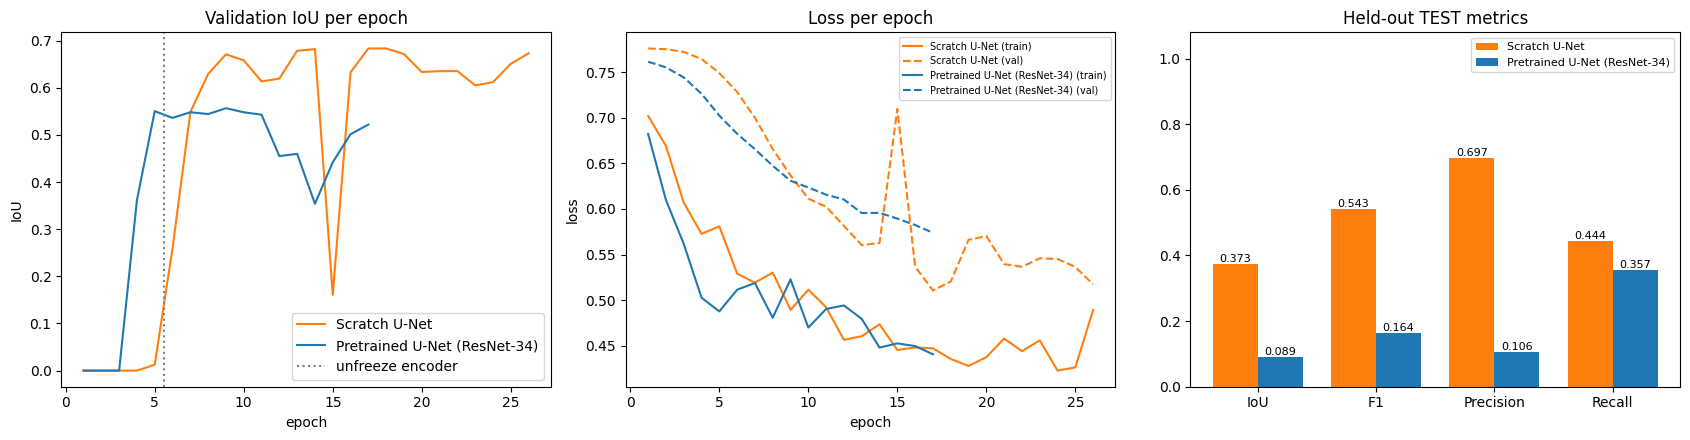

In [16]:
# 16. Training curves + metric bar chart
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
colors = {SCRATCH: "tab:orange", PRE: "tab:blue"}

for name, h in HISTORIES.items():
    axes[0].plot(h["epoch"], h["val_IoU"], label=name, color=colors[name])
    axes[1].plot(h["epoch"], h["train_loss"], label=f"{name} (train)", color=colors[name])
    axes[1].plot(h["epoch"], h["val_loss"], "--", label=f"{name} (val)", color=colors[name])
h = HISTORIES[PRE]
boundary = h.loc[h["phase"] == "2-finetune", "epoch"].min()
if pd.notna(boundary):
    axes[0].axvline(boundary - 0.5, color="gray", ls=":", label="unfreeze encoder")
axes[0].set(title="Validation IoU per epoch", xlabel="epoch", ylabel="IoU"); axes[0].legend()
axes[1].set(title="Loss per epoch", xlabel="epoch", ylabel="loss"); axes[1].legend(fontsize=7)

metrics = ["IoU", "F1", "Precision", "Recall"]
xpos = np.arange(len(metrics)); width = 0.38
for k, name in enumerate([SCRATCH, PRE]):
    vals = [test_table.loc[name, m] for m in metrics]
    bars = axes[2].bar(xpos + (k - 0.5) * width, vals, width, label=name, color=colors[name])
    axes[2].bar_label(bars, fmt="%.3f", fontsize=8)
axes[2].set_xticks(xpos); axes[2].set_xticklabels(metrics); axes[2].set_ylim(0, 1.08)
axes[2].set(title="Held-out TEST metrics"); axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(WORK_DIR / "comparison_plots.png", dpi=150)
plt.show()


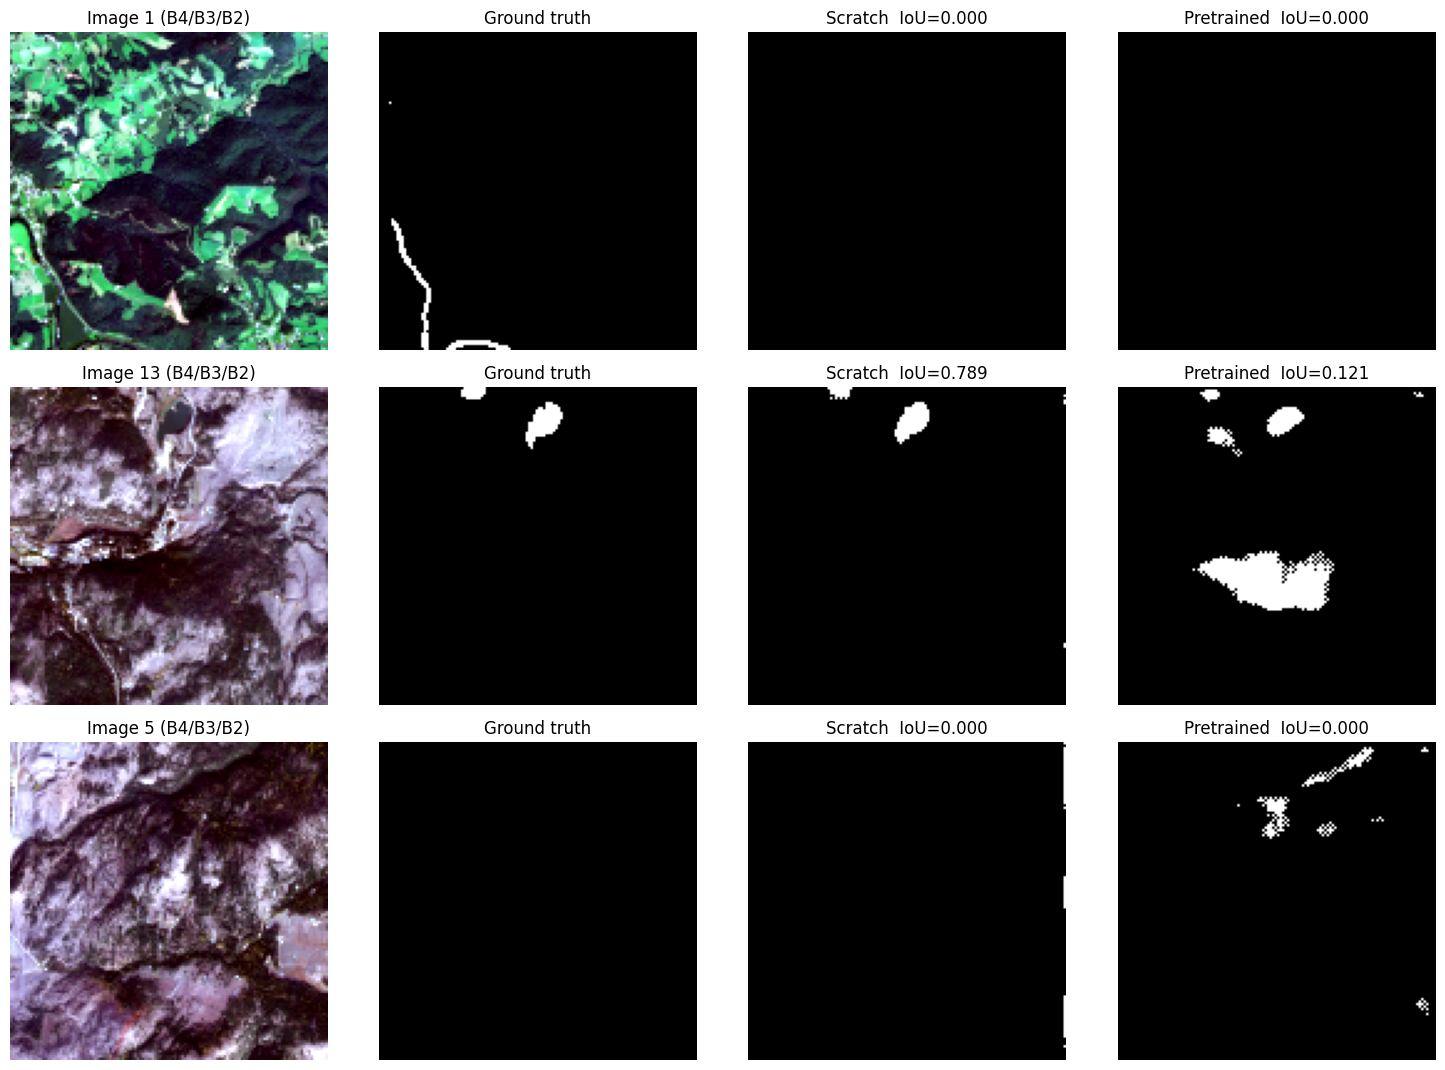

In [17]:
# 17. Qualitative comparison on test images: image | truth | scratch | pretrained
def predict_mask(model, i, thr):
    xb = torch.from_numpy(X[i:i+1]).float()
    if xb.shape[-2:] != (PATCH_SIZE, PATCH_SIZE):
        xb = F.interpolate(xb, size=(PATCH_SIZE, PATCH_SIZE), mode="bilinear", align_corners=False)
    model.eval()
    with torch.no_grad():
        return (torch.sigmoid(model(xb.to(DEVICE))).cpu().numpy()[0, 0] >= thr)

def resize_to_patch(arr, mode):
    t = torch.from_numpy(np.ascontiguousarray(arr)).float()
    if t.ndim == 2: t = t[None]
    t = F.interpolate(t[None], size=(PATCH_SIZE, PATCH_SIZE), mode=mode,
                      **({"align_corners": False} if mode == "bilinear" else {}))[0]
    return t.numpy()

n_show = min(4, len(test_idx))
fig, axes = plt.subplots(n_show, 4, figsize=(15, 3.6 * n_show))
axes = np.atleast_2d(axes)
for r, i in enumerate(test_idx[:n_show]):
    rgb = np.stack([X[i, RGB_BAND_IDX[0]], X[i, RGB_BAND_IDX[1]], X[i, RGB_BAND_IDX[2]]], axis=0)
    lo, hi = np.percentile(rgb, [2, 98]); rgb = np.clip((rgb - lo) / (hi - lo + 1e-6), 0, 1)
    rgb = resize_to_patch(rgb, "bilinear").transpose(1, 2, 0)
    truth = resize_to_patch(Y[i], "nearest")[0]
    ps = predict_mask(scratch_model, i, RESULTS[SCRATCH]["threshold"])
    pp = predict_mask(pre_model, i, RESULTS[PRE]["threshold"])
    def iou(p): return (p & (truth > .5)).sum() / max(((p | (truth > .5)).sum()), 1)
    axes[r, 0].imshow(rgb);                       axes[r, 0].set_title(f"Image {IDS[i]} (B4/B3/B2)")
    axes[r, 1].imshow(truth, cmap="gray");        axes[r, 1].set_title("Ground truth")
    axes[r, 2].imshow(ps, cmap="gray");           axes[r, 2].set_title(f"Scratch  IoU={iou(ps):.3f}")
    axes[r, 3].imshow(pp, cmap="gray");           axes[r, 3].set_title(f"Pretrained  IoU={iou(pp):.3f}")
    for ax in axes[r]: ax.axis("off")
plt.tight_layout()
plt.savefig(WORK_DIR / "prediction_comparison.png", dpi=150)
plt.show()


## 14. Final findings

In [18]:
# 18. Final findings (generated from the actual numbers above)
s_t, p_t = RESULTS[SCRATCH]["test"], RESULTS[PRE]["test"]
s_v, p_v = RESULTS[SCRATCH]["val"], RESULTS[PRE]["val"]
winner = PRE if p_t["IoU"] > s_t["IoU"] else SCRATCH

lines = [
    "========== FINAL FINDINGS ==========",
    f"Data: {len(pairs)} labelled 12-band images | train/val/test = {len(train_idx)}/{len(val_idx)}/{len(test_idx)}",
    "",
    f"1. 12-channel adaptation: first conv (64,3,7,7) -> {tuple(pre_model.conv1.weight.shape)}; "
    f"RGB filters mapped to B4/B3/B2, other bands initialised from the RGB mean.",
    f"2. Validation IoU:  scratch {s_v['IoU']:.4f}  vs  pretrained {p_v['IoU']:.4f}  "
    f"(gain {p_v['IoU'] - s_v['IoU']:+.4f}).",
    f"3. Test IoU:        scratch {s_t['IoU']:.4f}  vs  pretrained {p_t['IoU']:.4f}  "
    f"(gain {p_t['IoU'] - s_t['IoU']:+.4f}).",
    f"4. Test F1:         scratch {s_t['F1']:.4f}  vs  pretrained {p_t['F1']:.4f}.",
    f"5. Precision/Recall: scratch {s_t['Precision']:.3f}/{s_t['Recall']:.3f}  vs  "
    f"pretrained {p_t['Precision']:.3f}/{p_t['Recall']:.3f}.",
    f"6. Best model on the held-out test set: {winner}.",
    "",
    "Caveats:",
    f" - The test set has only {len(test_idx)} images, so differences of a few IoU points can be noise; "
    "re-running with several seeds / cross-validation would make the comparison robust.",
    " - ImageNet features were learned on RGB. Gains come mostly from better low-level/shape priors and "
    "faster, more stable convergence; the 9 non-RGB bands must still be learned by the first conv.",
    " - Pretrained model is larger than the scratch U-Net, so part of any gain may be capacity, not pretraining.",
    "",
    "Possible next steps: try EfficientNet/ResNet-50 encoders, add NDWI/MNDWI as extra channels, "
    "tile images into overlapping patches for more training samples, and test-time augmentation.",
]
FINDINGS = "\n".join(lines)
print(FINDINGS)
(WORK_DIR / "findings.txt").write_text(FINDINGS)


========== FINAL FINDINGS ==========
Data: 16 labelled 12-band images | train/val/test = 11/2/3

1. 12-channel adaptation: first conv (64,3,7,7) -> (64, 12, 7, 7); RGB filters mapped to B4/B3/B2, other bands initialised from the RGB mean.
2. Validation IoU:  scratch 0.6978  vs  pretrained 0.5566  (gain -0.1412).
3. Test IoU:        scratch 0.3725  vs  pretrained 0.0892  (gain -0.2833).
4. Test F1:         scratch 0.5428  vs  pretrained 0.1637.
5. Precision/Recall: scratch 0.697/0.444  vs  pretrained 0.106/0.357.
6. Best model on the held-out test set: Scratch U-Net.

Caveats:
 - The test set has only 3 images, so differences of a few IoU points can be noise; re-running with several seeds / cross-validation would make the comparison robust.
 - ImageNet features were learned on RGB. Gains come mostly from better low-level/shape priors and faster, more stable convergence; the 9 non-RGB bands must still be learned by the first conv.
 - Pretrained model is larger than the scratch U-Net, so 

1235

## 15. Export README (comparison table) and push to GitHub

The next cell writes `README.md` containing the comparison table with the real results. Then push with the commands below (run in a terminal or a `!` cell).

In [19]:
# 19. Write README.md with the comparison table
def md_table(table):
    hdr = "| Model | IoU | F1 | Precision | Recall | Threshold |\n|---|---|---|---|---|---|\n"
    body = "".join(f"| {n} | {r.IoU:.4f} | {r.F1:.4f} | {r.Precision:.4f} | {r.Recall:.4f} | {r.Threshold:.2f} |\n"
                   for n, r in table.iterrows())
    return hdr + body

readme = f"""# Water Segmentation — 12-channel Sentinel-2 (Scratch vs Pretrained U-Net)

Binary water segmentation on 12-band multispectral GeoTIFFs.

* **Model A (Week 1):** U-Net trained from scratch.
* **Model B (Week 2):** U-Net with an ImageNet-pretrained **ResNet-34** encoder whose first convolution is
  adapted from 3 to **12 input channels** (RGB filters mapped to B4/B3/B2, other bands initialised from
  the RGB mean, scaled by 3/12), fine-tuned in two phases (frozen-encoder warm-up -> full fine-tune with
  discriminative learning rates).

Same split (train/val/test = {len(train_idx)}/{len(val_idx)}/{len(test_idx)}), train-only normalisation, loss,
epoch budget and validation-only threshold selection for both models.

## Results

### Validation
{md_table(val_table)}
### Held-out test
{md_table(test_table)}
Validation IoU gain (pretrained - scratch): **{val_gain_thr:+.4f}** (tuned thresholds), **{val_gain_05:+.4f}** (best epoch, thr 0.5).

![comparison](comparison_plots.png)
![predictions](prediction_comparison.png)

## Findings
```
{FINDINGS}
```

## Reproduce
Open `water_segmentation_week2_pretrained_vs_scratch.ipynb` in Colab and run all cells.
Dependencies: torch, torchvision, rasterio, scikit-learn, pandas, matplotlib, gdown, tqdm.
"""
(WORK_DIR / "README.md").write_text(readme)
print(readme[:1800])


# Water Segmentation — 12-channel Sentinel-2 (Scratch vs Pretrained U-Net)

Binary water segmentation on 12-band multispectral GeoTIFFs.

* **Model A (Week 1):** U-Net trained from scratch.
* **Model B (Week 2):** U-Net with an ImageNet-pretrained **ResNet-34** encoder whose first convolution is
  adapted from 3 to **12 input channels** (RGB filters mapped to B4/B3/B2, other bands initialised from
  the RGB mean, scaled by 3/12), fine-tuned in two phases (frozen-encoder warm-up -> full fine-tune with
  discriminative learning rates).

Same split (train/val/test = 11/2/3), train-only normalisation, loss,
epoch budget and validation-only threshold selection for both models.

## Results

### Validation
| Model | IoU | F1 | Precision | Recall | Threshold |
|---|---|---|---|---|---|
| Scratch U-Net | 0.6978 | 0.8220 | 0.8497 | 0.7960 | 0.44 |
| Pretrained U-Net (ResNet-34) | 0.5566 | 0.7151 | 0.8248 | 0.6312 | 0.50 |

### Held-out test
| Model | IoU | F1 | Precision | Recall | Threshold |
|